# Genres over time
How the genre mix of listening changes from month to month, using each artist's cleaned tags.

## Load data
Uses `scrobbles.parquet` and `artist_tags.parquet` from the project folder, or `sample_data/` if they aren't there. Tags are cleaned with `clean_tags` from `tags.py`.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import PercentFormatter

from tags import clean_tags
from viz import BAR_COLOR, SURFACE, INK, MUTED, GRID, BASELINE, add_title, save_figure

DATA_DIR = '.' if os.path.exists('scrobbles.parquet') else 'sample_data'  # falls back to the bundled sample
print(f'data: {DATA_DIR}')

df = pd.read_parquet(f'{DATA_DIR}/scrobbles.parquet')
artist_tags = clean_tags(pd.read_parquet(f'{DATA_DIR}/artist_tags.parquet'))
print(df.shape, artist_tags.shape)

data: .
(34009, 5) (4974, 3)


## Monthly share by tag
For each month, the share of scrobbles whose artist has each of the top tags. A scrobble counts toward every tag its artist has, so the shares overlap and don't add up to 100%.

In [2]:
N_TAGS = 6  # how many of the top tags to chart

local = df['played_at'].dt.tz_localize(None)  # drop the timezone, keep local wall-clock time
month = local.dt.to_period('M').rename('month')
plays = df[['artist']].assign(month=month)

monthly_total = plays.groupby('month').size()  # all scrobbles in each month

pairs = artist_tags[['artist', 'tag']].drop_duplicates()
tagged = plays.merge(pairs, on='artist')  # one row per (scrobble, tag)
tag_counts = tagged.groupby(['month', 'tag']).size().unstack(fill_value=0)
tag_counts = tag_counts.reindex(monthly_total.index, fill_value=0)

top_tags = tag_counts.sum().nlargest(N_TAGS).index  # most-played tags over the whole history
shares = tag_counts[top_tags].div(monthly_total, axis=0) * 100  # percent of each month's scrobbles
shares.index = shares.index.to_timestamp()
shares.tail()

tag,indie,rock,alternative,electronic,indie pop,hip-hop
month,,,,,,
2026-07-01,35.992908,24.408983,23.345154,15.898345,16.252955,19.799054
2026-08-01,35.995624,31.728665,23.632385,17.943107,15.426696,17.505470
2026-09-01,30.902778,19.791667,18.055556,15.798611,16.319444,24.131944
2026-10-01,29.020556,20.677146,15.961306,16.203144,18.379686,18.379686
2026-11-01,29.764065,20.871143,15.970962,16.515426,14.156080,19.237750


## Small multiples
One panel per tag, all on the same scale so the panels can be compared.

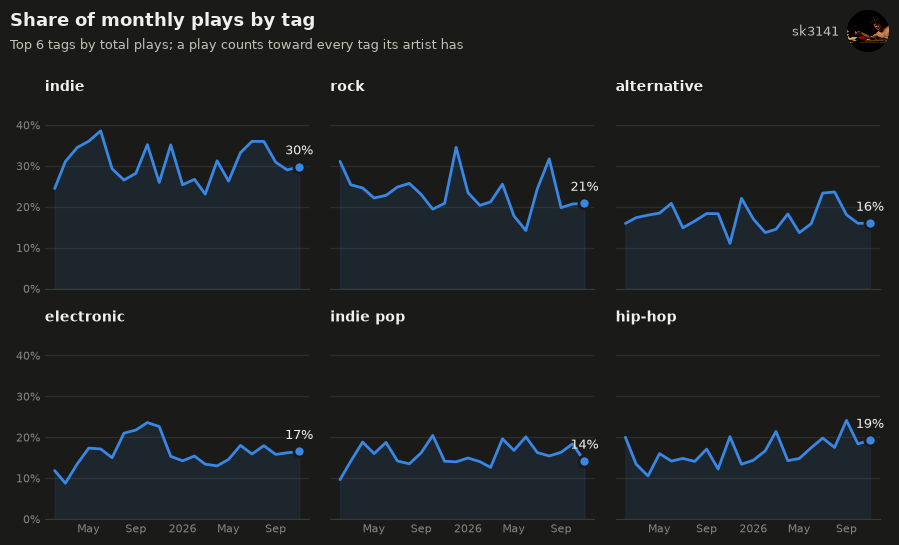

In [3]:
def plot_tag_shares(shares, save=False):
    '''Small multiples of each tag's monthly share of scrobbles, on a shared scale.'''
    n_cols = 3
    n_rows = -(-len(shares.columns) // n_cols)  # ceiling division
    height = 2.2 * n_rows + 1.1
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(9, height), sharex=True, sharey=True,
                             facecolor=SURFACE, squeeze=False)
    y_max = shares.max().max() * 1.2

    for ax, tag in zip(axes.flat, shares.columns):
        values = shares[tag]
        ax.set_facecolor(SURFACE)
        ax.plot(values.index, values.values, color=BAR_COLOR, linewidth=2, solid_capstyle='round')
        ax.fill_between(values.index, values.values, color=BAR_COLOR, alpha=0.1)

        # mark and label the latest month; the axis carries the rest
        ax.plot(values.index[-1], values.values[-1], 'o', markersize=8, color=BAR_COLOR,
                markeredgecolor=SURFACE, markeredgewidth=2)
        ax.annotate(f'{values.values[-1]:.0f}%', (values.index[-1], values.values[-1]),
                    textcoords='offset points', xytext=(0, 9), ha='center', fontsize=9, color=INK)

        ax.set_title(tag, loc='left', fontsize=10, fontweight='bold', color=INK)
        ax.set_ylim(0, y_max)
        ax.margins(x=0.04)
        ax.yaxis.grid(True, color=GRID, linewidth=1)
        ax.set_axisbelow(True)
        for side in ('top', 'right', 'left'):
            ax.spines[side].set_visible(False)
        ax.spines['bottom'].set_color(BASELINE)
        ax.tick_params(length=0, labelsize=8, labelcolor=MUTED)

    for ax in axes.flat[len(shares.columns):]:
        ax.set_visible(False)  # unused panels

    axes[0, 0].yaxis.set_major_formatter(PercentFormatter(100, decimals=0))
    locator = mdates.AutoDateLocator(minticks=4, maxticks=8)
    axes[0, 0].xaxis.set_major_locator(locator)
    axes[0, 0].xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))

    add_title(fig, 'Share of monthly plays by tag',
              f'Top {len(shares.columns)} tags by total plays; a play counts toward every tag its artist has', height)
    fig.tight_layout(rect=(0, 0, 1, 1 - 0.65 / height))
    if save:
        save_figure(fig, 'genre_share_over_time')
    plt.show()


plot_tag_shares(shares, save=True)